# Decision Tree on Drug Dataset
Predicting which drug (A, B, C, X or Y) suits a patient using age, sex, blood pressure, cholesterol and Na-to-K ratio.

## Load the data

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("drug200.csv")
df = df.drop_duplicates().reset_index(drop=True)
print("Missing values:\n",df.isnull().sum())
print("")
print(df["Drug"].value_counts())
print(df.shape)



Missing values:
 Age            0
Sex            0
BP             0
Cholesterol    0
Na_to_K        0
Drug           0
dtype: int64

Drug
drugY    91
drugX    54
drugA    23
drugC    16
drugB    16
Name: count, dtype: int64
(200, 6)


**Observation:** 200 patients, no missing values and no duplicate rows. drugY is the most common drug (91 patients) and drugB and drugC are the rarest (16 each).

## Turn the text columns into numbers
The decision tree only works with numbers. BP and Cholesterol keep their natural order (LOW < NORMAL < HIGH).

In [26]:
df["Sex"] = df["Sex"].map({"F":0, "M":1})
df["BP"] = df["BP"].map({"LOW":0, "NORMAL":1, "HIGH":2})
df["Cholesterol"] = df["Cholesterol"].map({"NORMAL":0, "HIGH":1})

features = ["Age", "Sex", "BP", "Cholesterol", "Na_to_K"]

df.head()

,Age,Sex,BP,Cholesterol,Na_to_K,Drug
0,23,0,2,1,25.355,drugY
1,47,1,0,1,13.093,drugC
2,47,1,0,1,10.114,drugC
3,28,0,1,1,7.798,drugX
4,61,0,0,1,18.043,drugY


**Observation:** Sex, BP and Cholesterol are now numbers (F=0, M=1; LOW=0, NORMAL=1, HIGH=2; NORMAL=0, HIGH=1). Drug stays as text because it is what we are predicting.

## Split into train and test

In [27]:
from sklearn.model_selection import train_test_split

X = df[features]
y = df["Drug"]

X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, random_state= 42, stratify=y)
print("Training patients:",len(X_train))
print("Testing patients:",len(X_test))

Training patients: 160
Testing patients: 40


**Observation:** 160 patients are used for training and 40 for testing. `stratify=y` keeps the same mix of drugs in both groups.

## Train the decision tree

In [28]:
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier(criterion="gini", random_state=42)
model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

**Observation:** The tree is trained on the 160 training patients using Gini impurity. The test patients are kept hidden until the next step.

## Predict and evaluate the model

In [29]:
from sklearn.metrics import accuracy_score, confusion_matrix

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", round(accuracy * 100,1), "%")
print(confusion_matrix(y_test, y_pred))

Accuracy: 97.5 %
[[ 5  0  0  0  0]
 [ 1  2  0  0  0]
 [ 0  0  3  0  0]
 [ 0  0  0 11  0]
 [ 0  0  0  0 18]]


**Observation:** 97.5% accuracy. Only 1 of the 40 test patients was wrong: a drugB patient predicted as drugA, because they were close to the age cutoff between the two drugs.

## Plot the decision tree

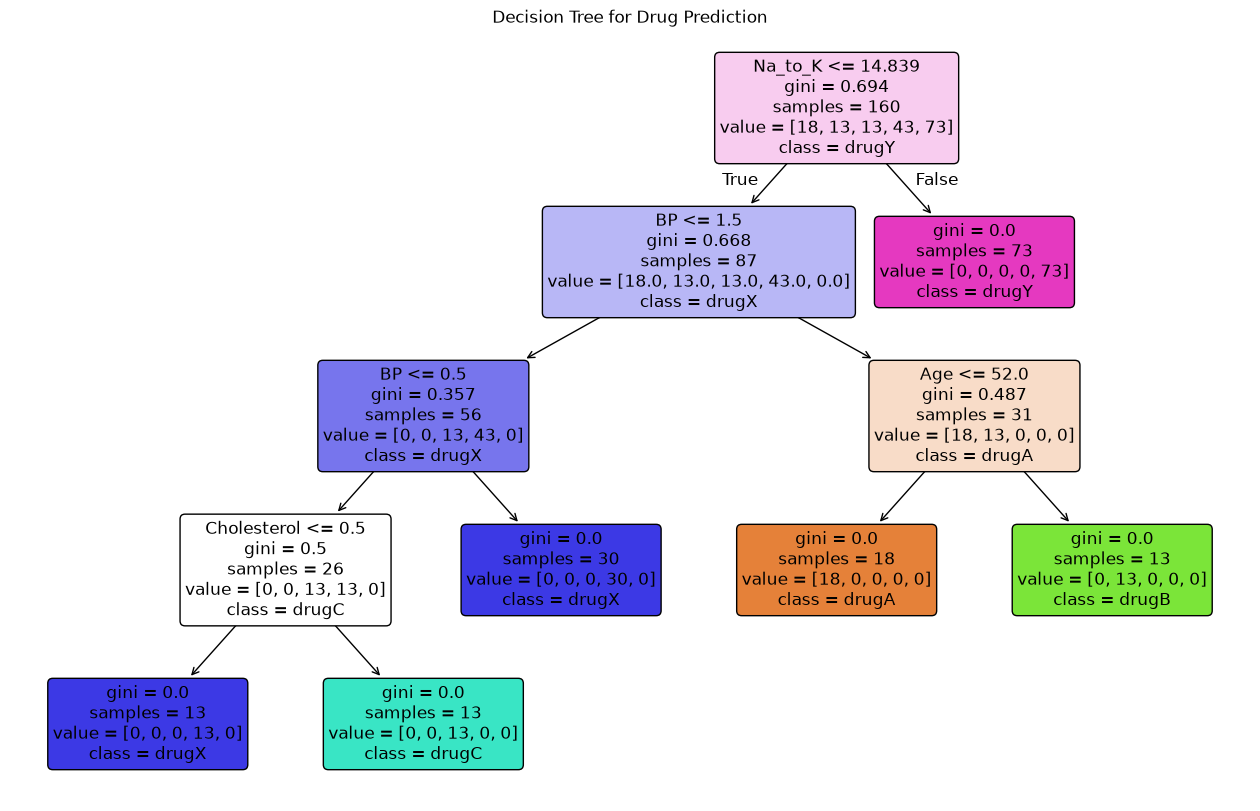

In [30]:
from sklearn.tree import plot_tree

plt.figure(figsize=(16, 10))
plot_tree(model, feature_names=features, class_names=model.classes_, filled=True, rounded=True, fontsize=12)
plt.title("Decision Tree for Drug Prediction")
plt.show()


**Observation:** The first question is Na_to_K ≤ 14.84, and every patient above that takes drugY. HIGH BP patients are split by age (≤ 52 → drugA, older → drugB), and LOW BP patients by cholesterol (HIGH → drugC, NORMAL → drugX). NORMAL BP patients get drugX. Sex is never used.

## Conclusions
- A decision tree (scikit-learn, Gini impurity) was used to predict which drug suits a patient from their age, sex, blood pressure, cholesterol and Na-to-K ratio.
- The model is 97.5% accurate on the test patients: 39 out of 40 were given the right drug.
- Na_to_K is the most important feature. Every patient with a ratio above about 14.84 takes drugY.
- Blood pressure separates the rest: HIGH BP patients get drugA or drugB depending on age, and LOW BP patients get drugC or drugX depending on cholesterol.
- The only mistake was a 51-year-old drugB patient predicted as drugA, because the tree learned the age cutoff as 52 instead of the true value of about 50.
- Sex is never used by the tree, so it does not affect which drug is given.